# Projet Machine Learning Avancé — Groupe 3
## Classification des émotions faciales sur FER2013 (PCA + Régression Logistique)

### Introduction *(Partie 4 — Évaluation et rédaction)*
> **TODO (Personne 4)** : Rédiger l'introduction du projet, présenter le dataset FER2013 (7 classes d'émotions, images 48×48 en niveaux de gris) et expliquer la méthodologie (extraction de caractéristiques via PCA + classification multiclasse par Régression Logistique avec `GridSearchCV`).


# Classification des émotions faciales — FER2013

## Partie 1 : Préparation et exploration des données

Objectif : télécharger le dataset FER2013, analyser sa structure,
visualiser les images et préparer leur chargement avec PyTorch.

## 1. Importation et décompression du dataset FER2013

Nous utilisons les bibliothèques glob et zipfile pour localiser et décompresser le fichier ZIP du dataset FER2013, afin d'accéder aux images d'entraînement et de test.

In [9]:
import glob
import zipfile

zip_files = glob.glob("/content/*.zip")
print("Fichiers ZIP trouvés :", zip_files)

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/data")

print("Décompression terminée")

Fichiers ZIP trouvés : ['/content/archive.zip']
Décompression terminée


In [10]:
print(os.listdir("/content/data"))

['train', 'test']


## 2. Exploration du dataset

Nous identifions les sept classes d'émotions présentes dans FER2013, puis nous analysons la répartition des images afin de repérer d'éventuels déséquilibres entre les catégories.

In [11]:
import os

train_path = "/content/data/train"
test_path = "/content/data/test"

classes = sorted(os.listdir(train_path))

print("Nombre de classes :", len(classes))
print("Liste des émotions :", classes)

Nombre de classes : 7
Liste des émotions : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


Nous comptons le nombre d'images pour chaque émotion afin d'observer la répartition des classes et de repérer d'éventuels déséquilibres.

In [12]:
images_par_classe = {}

for emotion in classes:
    dossier = os.path.join(train_path, emotion)
    nombre = len(os.listdir(dossier))

    images_par_classe[emotion] = nombre
    print(f"{emotion} : {nombre} images")

print("\nNombre total d'images :", sum(images_par_classe.values()))

angry : 3995 images
disgust : 436 images
fear : 4097 images
happy : 7215 images
neutral : 4965 images
sad : 4830 images
surprise : 3171 images

Nombre total d'images : 28709


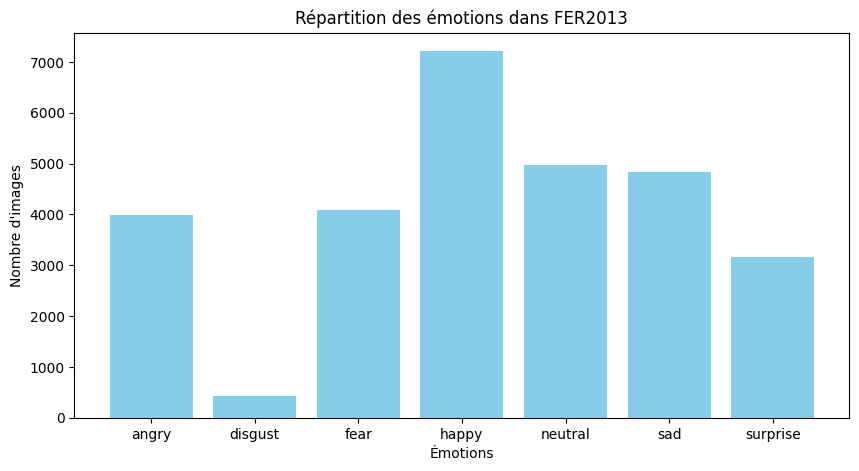

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    images_par_classe.keys(),
    images_par_classe.values(),
    color="skyblue"
)

plt.title("Répartition des émotions dans FER2013")
plt.xlabel("Émotions")
plt.ylabel("Nombre d'images")

plt.show()

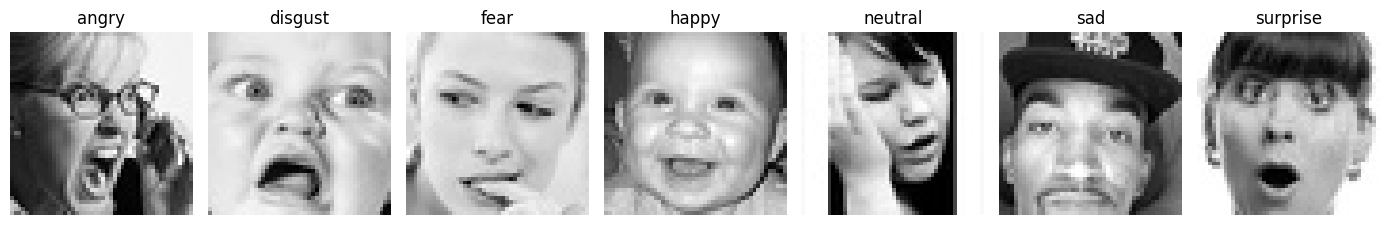

In [14]:
from PIL import Image
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(14, 4))

for i, emotion in enumerate(classes):
    dossier = os.path.join(train_path, emotion)
    fichier = os.listdir(dossier)[0]
    chemin = os.path.join(dossier, fichier)

    image = Image.open(chemin).convert("L")

    plt.subplot(1, 7, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(emotion)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
print("Dimensions de l'image :", image.size)

Dimensions de l'image : (48, 48)


In [16]:
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [17]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor()
])

In [18]:
train_dataset = datasets.ImageFolder(
    root="/content/data/train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root="/content/data/test",
    transform=transform
)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))
print("Classes :", train_dataset.classes)

Images d'entraînement : 28709
Images de test : 7178
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [19]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [20]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des labels :", labels.shape)

Dimensions des images : torch.Size([64, 1, 48, 48])
Dimensions des labels : torch.Size([64])


In [21]:
from torch.utils.data import random_split

# Fixer une graine pour reproduire les résultats
generator = torch.Generator().manual_seed(42)

# 85 % entraînement, 15 % validation
train_size = int(0.85 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_ds, val_ds = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Entraînement :", len(train_ds))
print("Validation :", len(val_ds))
print("Test :", len(test_dataset))

Entraînement : 24402
Validation : 4307
Test : 7178


In [22]:
train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Les 3 DataLoader sont prêts ")

Les 3 DataLoader sont prêts 


In [23]:
for nom, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    images, labels = next(iter(loader))

    print(nom)
    print("Images :", images.shape)
    print("Labels :", labels.shape)
    print()

Train
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])

Validation
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])

Test
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])



---
## Partie 2 : Prétraitement, conversion en vecteurs et PCA *(Personne 2)*

Objectif : convertir les lots d'images PyTorch (`DataLoader`) en vecteurs NumPy 1D (`48 × 48 = 2304` pixels) et appliquer une réduction de dimensionnalité par **PCA** (`n_components=150`).


In [ ]:
import numpy as np

def to_numpy(loader):
    """Convertit un DataLoader PyTorch en matrices NumPy (X, y) aplaties."""
    X, y = [], []
    for imgs, labels in loader:
        X.append(imgs.view(imgs.size(0), -1).numpy())
        y.append(labels.numpy())
    return np.vstack(X), np.hstack(y)




#2: test fictif

In [25]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Fausses images 1x48x48 avec de fausses classes (0 à 6)
fake_loader = DataLoader(
    TensorDataset(torch.rand(700, 1, 48, 48), torch.randint(0, 7, (700,))),
    batch_size=64)

# Test de to_numpy (attendu : X (700, 2304), y (700,))
X_fake, y_fake = to_numpy(fake_loader)
print("X :", X_fake.shape, "| y :", y_fake.shape)

# Test normalisation + PCA (attendu : (700, 150))
X_fake_pca = PCA(n_components=150, random_state=42).fit_transform(
    StandardScaler().fit_transform(X_fake))
print("Après PCA :", X_fake_pca.shape)

X : (700, 2304) | y : (700,)
Après PCA : (700, 150)


#3: Conversion des vrais DataLoaders




In [26]:
# Conversion des 3 DataLoaders en tableaux numpy
X_train, y_train = to_numpy(train_loader)
X_val, y_val = to_numpy(val_loader)
X_test, y_test = to_numpy(test_loader)

print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :", X_test.shape)
print("min/max avant normalisation :", X_train.min(), X_train.max())

Train : (24402, 2304) | Val : (4307, 2304) | Test : (7178, 2304)
min/max avant normalisation : 0.0 1.0


#4: normalisation

In [27]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Moyenne/écart-type (train) :", X_train.mean().round(3), X_train.std().round(3))

Moyenne/écart-type (train) : 0.0 1.0


#5: PCA

In [28]:
from sklearn.decomposition import PCA

# Fit sur le train uniquement, puis transform sur val et test
pca = PCA(n_components=150, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Après PCA :", X_train_pca.shape, X_val_pca.shape, X_test_pca.shape)
print("Variance expliquée cumulée :", pca.explained_variance_ratio_.sum())

Après PCA : (24402, 150) (4307, 150) (7178, 150)
Variance expliquée cumulée : 0.9182592


#6 : variance expliquée

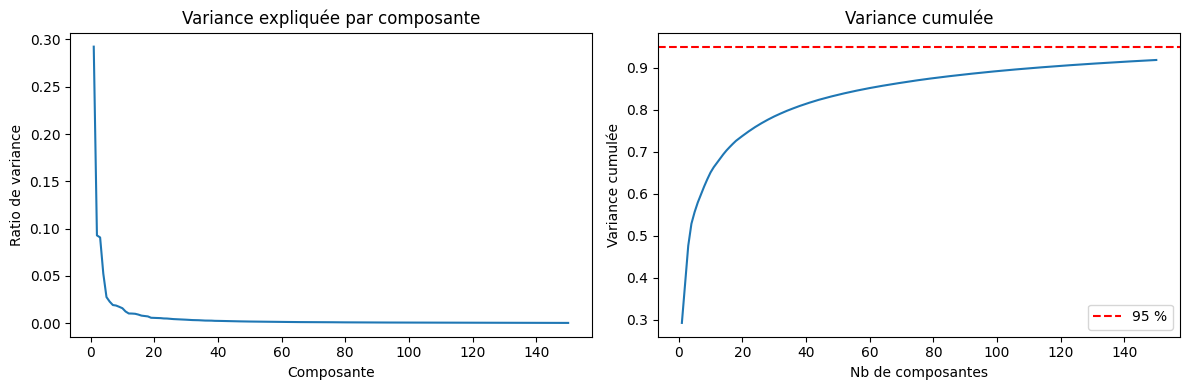

In [29]:
import matplotlib.pyplot as plt

var = pca.explained_variance_ratio_
cum = np.cumsum(var)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Variance par composante
ax[0].plot(range(1, len(var) + 1), var)
ax[0].set(title="Variance expliquée par composante", xlabel="Composante", ylabel="Ratio de variance")

# Variance cumulée : sert à justifier le nombre de composantes choisi
ax[1].plot(range(1, len(cum) + 1), cum)
ax[1].axhline(0.95, color="r", ls="--", label="95 %")
ax[1].set(title="Variance cumulée", xlabel="Nb de composantes", ylabel="Variance cumulée")
ax[1].legend()
plt.tight_layout()
plt.show()

#7 : bonus, premières composantes

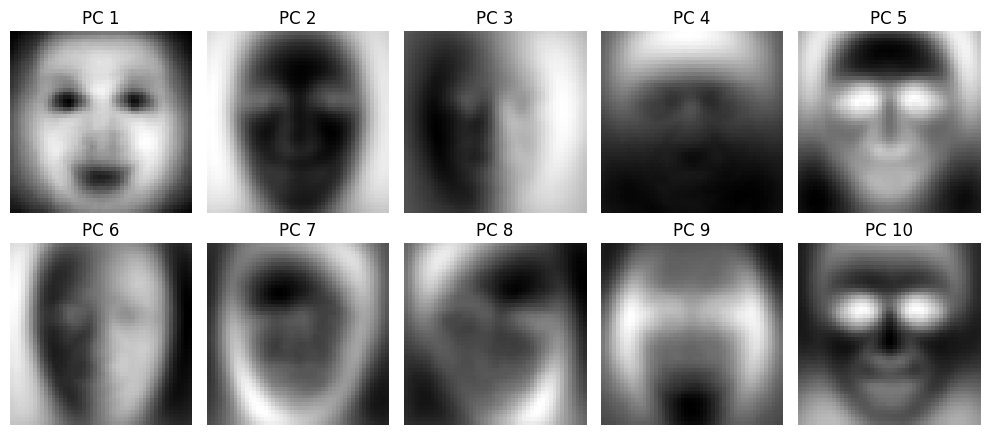

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    # Chaque composante (2304 valeurs) est remise en image 48x48
    ax.imshow(pca.components_[i].reshape(48, 48), cmap="gray")
    ax.set_title(f"PC {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## Partie 3 : Modèle — Régression Logistique et GridSearchCV *(Personne 3)*

Objectif : entraîner une régression logistique multiclasse et optimiser l'hyperparamètre de régularisation `C` par validation croisée (`GridSearchCV`).


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# TODO (Personne 3) : Tester d'abord sur des données fictives à 7 classes, puis entraîner sur X_train_pca
# logreg = LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=300, random_state=42)
# params = {"C": [0.1, 1, 3, 10]}
#
# clf = GridSearchCV(logreg, params, cv=3, n_jobs=-1, verbose=1)
# clf.fit(X_train_pca, y_train)
#
# print("Meilleurs hyperparamètres :", clf.best_params_)
# print("Accuracy (Validation) :", clf.score(X_val_pca, y_val))


---
## Partie 4 : Évaluation finale et visualisation *(Personne 4)*

Objectif : évaluer le meilleur modèle sur le jeu de test avec `accuracy_score`, `classification_report` et la matrice de confusion.


In [32]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# TODO (Personne 4) : Évaluer sur X_test_pca et tracer la matrice de confusion
# y_pred = clf.predict(X_test_pca)
# print("Accuracy (Test) :", accuracy_score(y_test, y_pred))
# print(classification_report(y_test, y_pred, target_names=classes))
#
# cm = confusion_matrix(y_test, y_pred)
# plt.figure(figsize=(8, 6))
# sns.heatmap(cm, cmap="Blues", annot=True, fmt="d", xticklabels=classes, yticklabels=classes)
# plt.title("Matrice de confusion — FER2013 (Test)")
# plt.xlabel("Prédictions")
# plt.ylabel("Vérité terrain")
# plt.tight_layout()
# plt.show()
